In [1]:
print("Student Performance Prediction Using Machine Learning")

Student Performance Prediction Using Machine Learning


In [3]:
%pip install pandas numpy matplotlib seaborn scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [43]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("All libraries imported successfully!")

All libraries imported successfully!


In [44]:
%pip install ucimlrepo

Note: you may need to restart the kernel to use updated packages.


In [45]:
from ucimlrepo import fetch_ucirepo

# Download the real Student Performance dataset
student_data = fetch_ucirepo(id=320)

print("Dataset downloaded successfully!")

Dataset downloaded successfully!


In [46]:
# Combine the dataset features and target columns
df = pd.concat(
    [student_data.data.features, student_data.data.targets],
    axis=1
)

# Display dataset information
print("Dataset loaded successfully!")
print("Number of rows and columns:", df.shape)

# Display the first 5 records
display(df.head())

Dataset loaded successfully!
Number of rows and columns: (649, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13


In [47]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 649 entries, 0 to 648
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      649 non-null    object
 1   sex         649 non-null    object
 2   age         649 non-null    int64 
 3   address     649 non-null    object
 4   famsize     649 non-null    object
 5   Pstatus     649 non-null    object
 6   Medu        649 non-null    int64 
 7   Fedu        649 non-null    int64 
 8   Mjob        649 non-null    object
 9   Fjob        649 non-null    object
 10  reason      649 non-null    object
 11  guardian    649 non-null    object
 12  traveltime  649 non-null    int64 
 13  studytime   649 non-null    int64 
 14  failures    649 non-null    int64 
 15  schoolsup   649 non-null    object
 16  famsup      649 non-null    object
 17  paid        649 non-null    object
 18  activities  649 non-null    object
 19  nursery     649 non-null    object
 20  higher    

In [48]:
df.isnull().sum()

school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64

In [49]:
df.duplicated().sum()

np.int64(0)

In [50]:
df.shape

(649, 33)

In [51]:
df.describe()

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000
mean,16.744222,2.514638,2.306626,1.568567,1.930663,0.221880,3.930663,3.180277,3.184900,1.502311,2.280431,3.536210,3.659476,11.399076,11.570108,11.906009
std,1.218138,1.134552,1.099931,0.748660,0.829510,0.593235,0.955717,1.051093,1.175766,0.924834,1.284380,1.446259,4.640759,2.745265,2.913639,3.230656
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,16.000000,2.000000,1.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,2.000000,0.000000,10.000000,10.000000,10.000000
50%,17.000000,2.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,2.000000,11.000000,11.000000,12.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,6.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,32.000000,19.000000,19.000000,19.000000


In [15]:
df['G3'].value_counts().sort_index()

G3
0      15
1       1
5       1
6       3
7      10
8      35
9      35
10     97
11    104
12     72
13     82
14     63
15     49
16     36
17     29
18     15
19      2
Name: count, dtype: int64

In [16]:
df['G3'].value_counts().sort_index()

G3
0      15
1       1
5       1
6       3
7      10
8      35
9      35
10     97
11    104
12     72
13     82
14     63
15     49
16     36
17     29
18     15
19      2
Name: count, dtype: int64

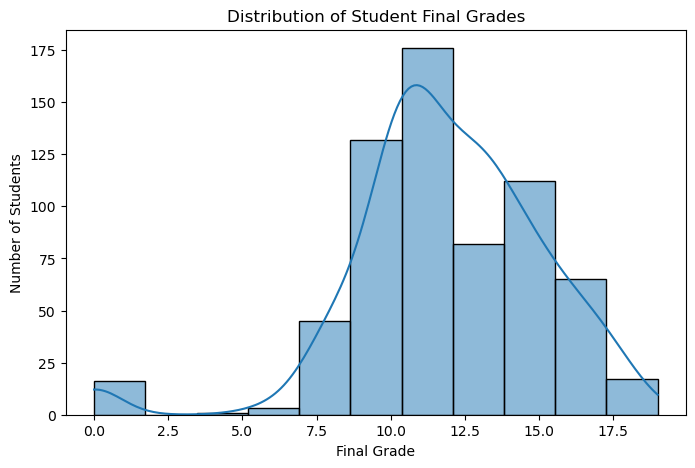

In [17]:
plt.figure(figsize=(8, 5))
sns.histplot(df['G3'], bins=11, kde=True)
plt.xlabel('Final Grade')
plt.ylabel('Number of Students')
plt.title('Distribution of Student Final Grades')
plt.show()

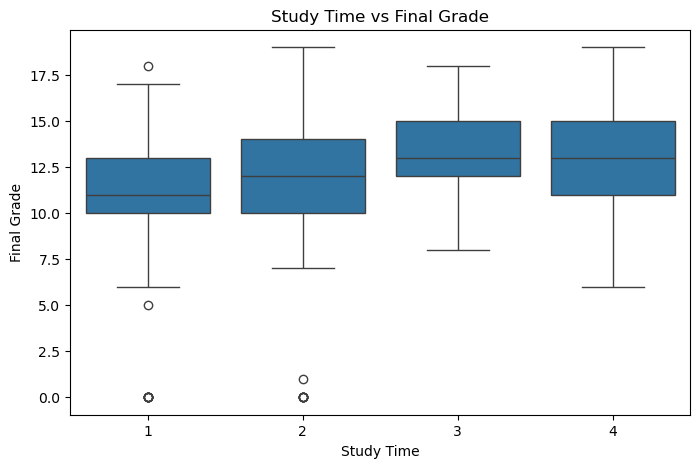

In [18]:
plt.figure(figsize=(8, 5))
sns.boxplot(x='studytime', y='G3', data=df)
plt.xlabel('Study Time')
plt.ylabel('Final Grade')
plt.title('Study Time vs Final Grade')
plt.show()

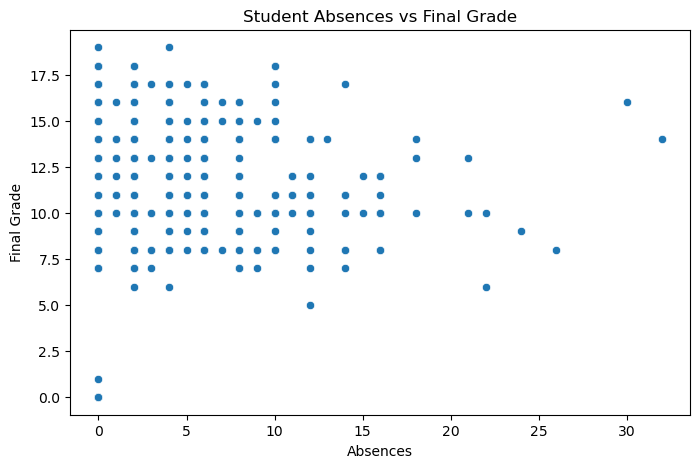

In [19]:
plt.figure(figsize=(8, 5))
sns.scatterplot(x='absences', y='G3', data=df)
plt.xlabel('Absences')
plt.ylabel('Final Grade')
plt.title('Student Absences vs Final Grade')
plt.show()

In [21]:
X = df.drop('G3', axis=1)
y = df['G3']

In [22]:
X = pd.get_dummies(X, drop_first=True, dtype=int)

In [23]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [24]:
X_train.shape, X_test.shape

((519, 41), (130, 41))

In [25]:
from sklearn.linear_model import LinearRegression

lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [26]:
y_pred = lr_model.predict(X_test)

In [27]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Mean Absolute Error:", mean_absolute_error(y_test, y_pred))
print("Mean Squared Error:", mean_squared_error(y_test, y_pred))
print("R2 Score:", r2_score(y_test, y_pred))

Mean Absolute Error: 0.7650597682758268
Mean Squared Error: 1.4759092563639336
R2 Score: 0.8486513286537312


In [29]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

,n_estimators,100
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [30]:
rf_pred = rf_model.predict(X_test)

In [31]:
print("Mean Absolute Error:", mean_absolute_error(y_test, rf_pred))
print("Mean Squared Error:", mean_squared_error(y_test, rf_pred))
print("R2 Score:", r2_score(y_test, rf_pred))

Mean Absolute Error: 0.7460769230769232
Mean Squared Error: 1.5398115384615385
R2 Score: 0.8420984017378219


In [32]:
comparison = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest'],
    'MAE': [
        mean_absolute_error(y_test, y_pred),
        mean_absolute_error(y_test, rf_pred)
    ],
    'MSE': [
        mean_squared_error(y_test, y_pred),
        mean_squared_error(y_test, rf_pred)
    ],
    'R2 Score': [
        r2_score(y_test, y_pred),
        r2_score(y_test, rf_pred)
    ]
})

comparison

,Model,MAE,MSE,R2 Score
0,Linear Regression,0.765060,1.475909,0.848651
1,Random Forest,0.746077,1.539812,0.842098


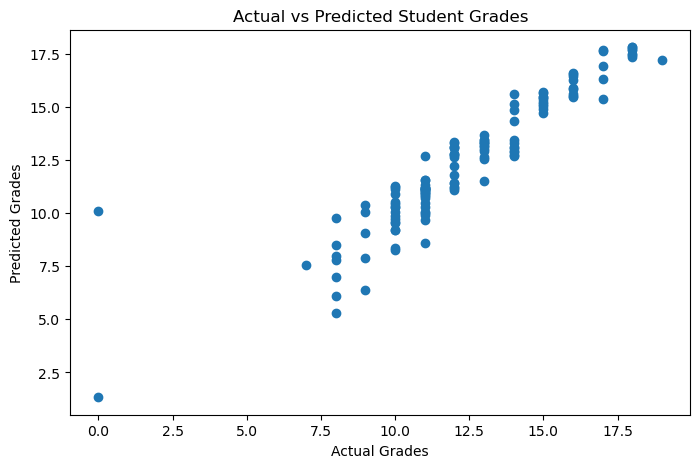

In [33]:
plt.figure(figsize=(8, 5))
plt.scatter(y_test, rf_pred)
plt.xlabel('Actual Grades')
plt.ylabel('Predicted Grades')
plt.title('Actual vs Predicted Student Grades')
plt.show()

In [34]:
results = pd.DataFrame({
    'Actual Grade': y_test.values,
    'Predicted Grade': rf_pred.round(2)
})

results.head(15)

,Actual Grade,Predicted Grade
0,19,17.23
1,12,11.12
2,18,17.38
3,11,11.09
4,11,11.20
5,17,16.34
6,18,17.47
7,8,9.79
8,10,10.31
9,11,10.47


In [35]:
importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf_model.feature_importances_
})

importance = importance.sort_values(
    by='Importance',
    ascending=False
)

importance.head(15)

,Feature,Importance
14,G2,0.827115
12,absences,0.035854
13,G1,0.019740
0,age,0.008999
7,freetime,0.008060
9,Dalc,0.007257
1,Medu,0.007206
15,school_MS,0.006518
6,famrel,0.006308
8,goout,0.006013


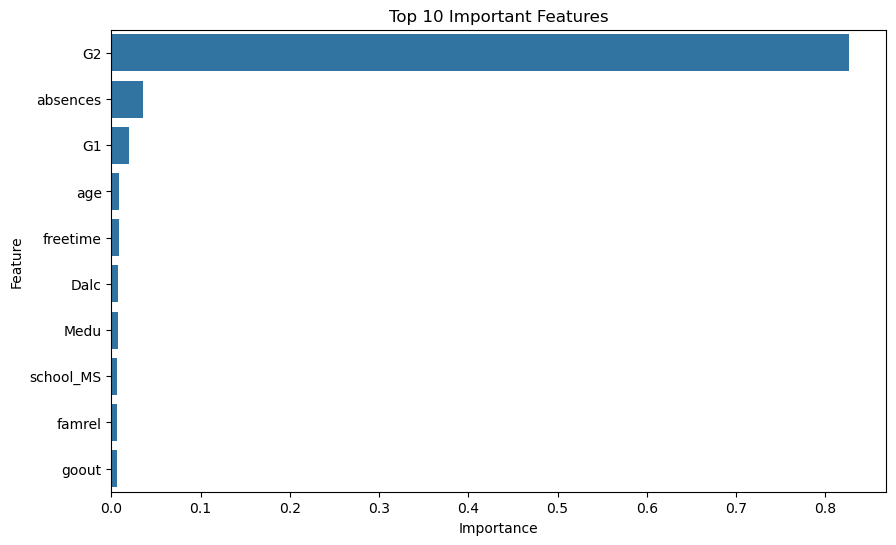

In [36]:
plt.figure(figsize=(10, 6))
sns.barplot(
    data=importance.head(10),
    x='Importance',
    y='Feature'
)
plt.title('Top 10 Important Features')
plt.show()

In [37]:
def predict_student_grade(student_details):
    student = pd.DataFrame([student_details])
    student = pd.get_dummies(student, dtype=int)
    student = student.reindex(columns=X.columns, fill_value=0)

    prediction = rf_model.predict(student)[0]

    return round(float(np.clip(prediction, 0, 20)), 2)

In [38]:
sample_student = df.drop('G3', axis=1).iloc[0].to_dict()

predicted_grade = predict_student_grade(sample_student)

print("Predicted Final Grade:", predicted_grade)
print("Actual Final Grade:", df['G3'].iloc[0])

Predicted Final Grade: 10.82
Actual Final Grade: 11


In [39]:
import joblib

joblib.dump(rf_model, 'student_performance_model.pkl')

['student_performance_model.pkl']

In [40]:
df.to_csv('student_performance_dataset.csv', index=False)

In [41]:
comparison.to_csv('model_comparison.csv', index=False)

In [42]:
comparison

,Model,MAE,MSE,R2 Score
0,Linear Regression,0.765060,1.475909,0.848651
1,Random Forest,0.746077,1.539812,0.842098


In [52]:
df.shape



(649, 33)

In [53]:
lr_model

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [54]:
rf_model

,n_estimators,100
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [55]:
results.head(10)

,Actual Grade,Predicted Grade
0,19,17.23
1,12,11.12
2,18,17.38
3,11,11.09
4,11,11.20
5,17,16.34
6,18,17.47
7,8,9.79
8,10,10.31
9,11,10.47


In [56]:
comparison

,Model,MAE,MSE,R2 Score
0,Linear Regression,0.765060,1.475909,0.848651
1,Random Forest,0.746077,1.539812,0.842098


In [57]:
import os
os.listdir()

['.ipynb_checkpoints',
 'model_comparison.csv',
 'student_performance_dataset.csv',
 'student_performance_model.pkl',
 'Student_Performance_Prediction.ipynb']

In [58]:
import os
os.getcwd()

'C:\\Users\\pavan\\Student_Performance_Prediction'

In [59]:
import os

os.listdir(r'C:\Users\pavan\Student_Performance_Prediction')

['.ipynb_checkpoints',
 'model_comparison.csv',
 'student_performance_dataset.csv',
 'student_performance_model.pkl',
 'Student_Performance_Prediction.ipynb']

In [61]:
import os
os.startfile(r'C:\Users\pavan\Student_Performance_Prediction')